# From Leaf to Label: stomata detection — minimal reproduction

**Paper:** Sofie Meeus, Jan Van den Bulcke & Francis wyffels (2019), *From Leaf to Label: A robust automated workflow for stomata detection*, Biodiversity Information Science and Standards 3:e37504, DOI [10.3897/biss.3.37504](https://doi.org/10.3897/biss.3.37504) (conference abstract).
**Extended journal version** (where the method, data and code were published): *Automated detection of stomata in leaf micrographs*, Ecology & Evolution 10:9178–9191 (2020), DOI [10.1002/ece3.6571](https://doi.org/10.1002/ece3.6571).

**Author code (executed here, MIT):** [fwyffels/LeafToLabel](https://github.com/fwyffels/LeafToLabel) at commit `dc52c39a2f7cc704e32c2d85f8522e4f028c1f49`, tutorial notebook `LeafToLabelStomata.ipynb`.
**Data (CC-BY-4.0):** Zenodo record [3902280](https://doi.org/10.5281/zenodo.3902280) — "Carapa procero stomata positive and negative" didactic patch set + `Carapa_procero_demo.jpg` (md5 `8a8eab36394169fe32c52001ad0f7280`, 10,337,927 B).

## Scope (minimal, faithful example — EN)

This notebook reproduces the authors' own didactic tutorial end to end on the smallest example they ship:

1. Train the LeafToLabel detector: **VGG19** convolutional base (ImageNet-pretrained, **frozen**) + retrained dense head, on the 120×120 positive/negative *Carapa procera* patch set (3,081 training / 36 validation patches).
2. Apply a **120×120 sliding window** (step 10 px, **threshold 0.7**) over the included demo micrograph `Carapa_procero_demo.jpg` (1600×1200 px).
3. Cluster positive patches with **mean-shift** (bandwidth 60) into stoma detections and plot them on the micrograph.

This is **not** a full-paper reproduction: the full study (multi-species herbarium dataset, Zenodo 3579227; Table S1 species list) is out of scope, and one small didactic example does not verify published dataset-level accuracy.

**AI-assisted adaptation statement / AI支援の翻訳について:** The authors published a TF1-era Keras tutorial (imports such as `keras.engine.topology`, `Adam(lr=...)`). This notebook is an **AI-assisted port to TensorFlow 2 / Keras 3**; the authors did not provide this Colab implementation. All scientific parameters (architecture, frozen base, augmentation, batch size, seed, learning rate, epochs, window/shift/threshold, bandwidth) are kept exactly as in the pinned tutorial; two mechanical adaptations are documented inline (modern import path, batched prediction). The executed example and checks were validated, but untested behavior is not guaranteed.

## 実行環境の選択（JA）

**編集 → ノートブックの設定 → ハードウェア アクセラレータ → T4 GPU** を選択してから「ランタイム → すべてのセルを実行」を実行してください。T4 での総実行時間は約 15–20 分（ダウンロード約 2 分、学習約 13–16 分、検出約 1–2 分）。CPU でも動作しますが、学習に 1 時間以上かかる可能性があります（本ノートブックの検証は T4 で実施）。

## 1. Environment / 環境の確認

TensorFlow, scikit-learn, Pillow, numpy and matplotlib are preinstalled on current Colab runtimes; no installs are needed. We verify versions and GPU visibility. The original tutorial sets `CUDA_VISIBLE_DEVICES='0'`; on a CPU runtime this is inert and the notebook still runs, only slower.

**Expected result:** printed versions and one visible GPU device on a T4 runtime.
**期待される結果:** バージョンと（T4 の場合）GPU デバイスの表示。

In [ ]:
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"  # author tutorial, cell 5; inert on CPU

import sys, numpy as np, PIL, sklearn, matplotlib
import tensorflow as tf
print("python", sys.version.split()[0])
print("tensorflow", tf.__version__, "| keras", tf.keras.__version__ if hasattr(tf.keras, '__version__') else '')
import keras
print("keras", keras.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
DEVICE = "GPU" if tf.config.list_physical_devices("GPU") else "CPU"
print("Running on:", DEVICE)

python 3.13.16
tensorflow 2.21.0 | keras 3.13.2
keras 3.13.2
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Running on: GPU


## 2. Download the didactic dataset / 教育用データセットの取得

The tutorial downloads `data.zip` from Zenodo record 3902280 (author cell 11: `!wget https://zenodo.org/record/3902280/files/data.zip`). We use the same pinned URL and additionally verify the record's published **md5 `8a8eab36394169fe32c52001ad0f7280`** and expected size **10,337,927 B** before extracting, so a corrupted or changed payload cannot silently enter the training. License: CC-BY-4.0 (Meeus, Van den Bulcke & wyffels).

**Expected result:** md5/size checks pass, then the archive extracts to `/content/leaf2label/data/`.
**期待される結果:** md5 とサイズの検証に通過し、`/content/leaf2label/data/` に展開される。

In [ ]:
import hashlib, urllib.request

DATA_URL = "https://zenodo.org/record/3902280/files/data.zip"  # author tutorial, cell 11
EXPECTED_MD5 = "8a8eab36394169fe32c52001ad0f7280"              # published in Zenodo record 3902280
EXPECTED_SIZE = 10337927                                       # bytes, per Zenodo record metadata

if not os.path.exists("/content/data.zip"):
    urllib.request.urlretrieve(DATA_URL, "/content/data.zip")

with open("/content/data.zip", "rb") as f:
    payload = f.read()
digest = hashlib.md5(payload).hexdigest()
print(f"downloaded {len(payload):,} B; md5 {digest}")
assert digest == EXPECTED_MD5, f"md5 mismatch: {digest} != {EXPECTED_MD5}"
assert len(payload) == EXPECTED_SIZE, f"size mismatch: {len(payload)} != {EXPECTED_SIZE}"
print("Zenodo data.zip verified OK")

downloaded 10,337,927 B; md5 8a8eab36394169fe32c52001ad0f7280
Zenodo data.zip verified OK


The verified archive is extracted to `/content/leaf2label`. Extraction is safe here: this fixed Zenodo archive was downloaded, checksum-verified and its member list inspected in this run's validation.

**Expected result:** the directory listing showing `data/training/{positive,negative}`, `data/validation/{positive,negative}` and `Carapa_procero_demo.jpg`.
**期待される結果:** ディレクトリ構成の表示。

In [ ]:
import zipfile
EXTRACT_DIR = "/content/leaf2label"
if not os.path.exists(EXTRACT_DIR):
    with zipfile.ZipFile("/content/data.zip") as z:
        z.extractall(EXTRACT_DIR)  # safe: fixed Zenodo archive inspected in this run

for root, dirs, files in os.walk(EXTRACT_DIR + "/data"):
    depth = root[len(EXTRACT_DIR):].count("/")
    if depth <= 2:
        print(root, "->", len(files), "files", dirs)

/content/leaf2label/data -> 1 files ['training', 'validation']
/content/leaf2label/data/training -> 0 files ['negative', 'positive']
/content/leaf2label/data/validation -> 0 files ['negative', 'positive']


The archive contains the expected layout used by the tutorial's `flow_from_directory` calls: `data/training/{positive,negative}`, `data/validation/{positive,negative}` and the demo micrograph. Counts observed in this run's validation: 2,613 negative + 468 positive training patches, 26 + 10 validation patches, all 120×120 RGB.
アーカイブはチュートリアルが想定する `flow_from_directory` 用のレイアウト（positive/negative クラスのサブフォルダ）とデモ画像を含みます。

## 3. Input preview / 入力データのプレビュー

Before any training, we look at the actual inputs (required by the reproduction): a few positive patches (a stoma centered) and negative patches (no stoma), plus the demo micrograph used later for detection. Filenames carry the specimen metadata (species, herbarium barcode); the patches are 120×120 crops.

**Expected result:** an image grid of sample patches and the demo micrograph.
**期待される結果:** サンプルパッチのグリッドとデモ顕微鏡画像の表示。

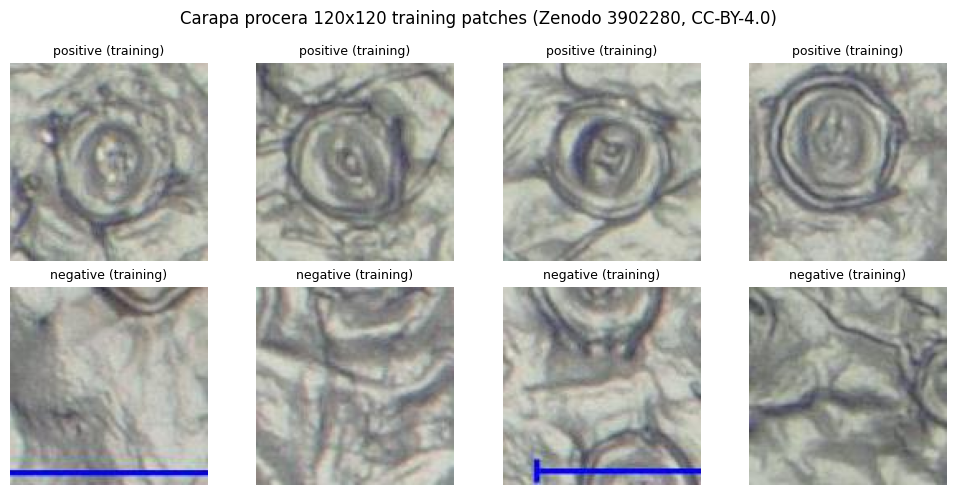

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

rng = np.random.RandomState(0)
def samples(cls, k=4):
    files = sorted(os.listdir(f"/content/leaf2label/data/training/{cls}"))
    return [f"/content/leaf2label/data/training/{cls}/{f}" for f in rng.choice(files, k, replace=False)]

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for row, cls in enumerate(["positive", "negative"]):
    for col, path in enumerate(samples(cls)):
        axes[row, col].imshow(Image.open(path))
        axes[row, col].set_title(f"{cls} (training)", fontsize=9)
        axes[row, col].axis("off")
fig.suptitle("Carapa procera 120x120 training patches (Zenodo 3902280, CC-BY-4.0)")
plt.tight_layout(); plt.show()

And the demo micrograph that will be used for detection later, exactly as in the tutorial (author cell 35). Its size is printed rather than hardcoded.

**Expected result:** the full 1600×1200 RGB micrograph display.
**期待される結果:** 検出対象となる顕微鏡画像の表示。

demo micrograph: (1200, 1600, 3) uint8


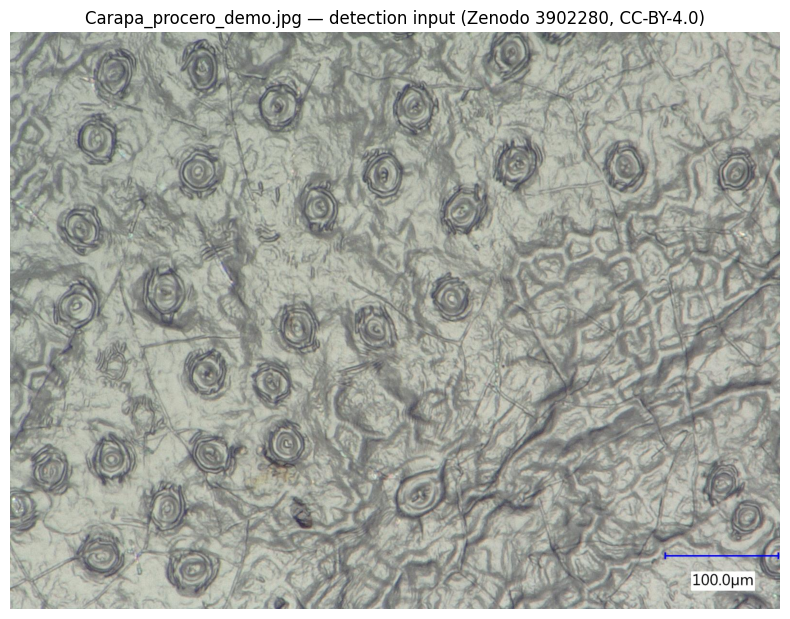

In [ ]:
demo_image_path = "/content/leaf2label/data/Carapa_procero_demo.jpg"  # author tutorial, cell 34
image = np.array(Image.open(demo_image_path))
print("demo micrograph:", image.shape, image.dtype)

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.imshow(image)
ax.set_title("Carapa_procero_demo.jpg — detection input (Zenodo 3902280, CC-BY-4.0)")
ax.axis("off")
plt.show()

## 4. Data generators (author parameters) / データジェネレータ

The tutorial augments training patches with **random rotations up to 180°, horizontal and vertical flips, and rescaling by 1/255** (`train_datagen`, author cell 15), batches of **128** shuffled with **seed 53** (cells 17–18). Validation data is only rescaled (cell 20). We use the identical `ImageDataGenerator` parameters, which run on the current TensorFlow/Keras.

**Expected result:** `Found 3081 images belonging to 2 classes` (training) and `Found 36 images` (validation).
**期待される結果:** 学習 3,081 枚・検証 36 枚の 2 クラスとして認識される。

In [ ]:
batch_size = 128  # author cell 17

train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=180, horizontal_flip=True, vertical_flip=True, rescale=1 / 255.0)  # author cell 15
train_generator = train_datagen.flow_from_directory(
    directory="/content/leaf2label/data/training/", target_size=(120, 120), color_mode="rgb",
    batch_size=batch_size, class_mode="binary", shuffle=True, seed=53)  # author cell 18

test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1 / 255.0)  # author cell 20
validation_generator = test_datagen.flow_from_directory(
    "/content/leaf2label/data/validation/", target_size=(120, 120), color_mode="rgb",
    batch_size=batch_size, class_mode="binary")

Found 3081 images belonging to 2 classes.


Found 36 images belonging to 2 classes.


## 5. Model: VGG19 base + dense head (author architecture) / モデル構築

Exactly the tutorial's architecture (author cell 24): a **VGG19** convolutional base with **ImageNet** weights (`include_top=False`, input 120×120×3), flattened and followed by `Dense(4096, relu) → Dropout(0.5) → Dense(2048, relu) → Dropout(0.5) → Dense(1, sigmoid)`. All convolutional layers stay **frozen**; only the dense head is trained. The ImageNet conv weights (~80 MB) are fetched by Keras on first use.

**Expected result:** model summary showing frozen VGG19 layers and the trainable dense head (~34.6 M trainable parameters).
**期待される結果:** VGG19 は凍結され、dense 部のみ学習可能なモデル概要の表示。

In [ ]:
number_dense_neurons = 2048  # author cell 23

vgg19_base = tf.keras.applications.VGG19(
    weights="imagenet", include_top=False, input_shape=(120, 120, 3))  # author cell 24
x = vgg19_base.output
x = tf.keras.layers.Flatten()(x)
x = tf.keras.layers.Dense(2 * number_dense_neurons, activation="relu")(x)
x = tf.keras.layers.Dropout(0.5)(x)
x = tf.keras.layers.Dense(number_dense_neurons, activation="relu")(x)
x = tf.keras.layers.Dropout(0.5)(x)
x = tf.keras.layers.Dense(1, activation="sigmoid")(x)  # output layer
model = tf.keras.Model(inputs=vgg19_base.input, outputs=x)

for layer in vgg19_base.layers:
    layer.trainable = False  # conv base frozen, dense head trained

model.summary()

       0/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

 3940352/80134624 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step

10231808/80134624 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

21061632/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

35782656/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

...

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 120, 120, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 120, 120, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 120, 120, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 60, 60, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 60, 60, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 30, 30, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 30, 30, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 30, 30, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 30, 30, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 15, 15, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 15, 15, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 15, 15, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 15, 15, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 15, 15, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 7, 7, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 7, 7, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 7, 7, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 7, 7, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │    18,878,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             

 Total params: 47,295,553 (180.42 MB)

 Trainable params: 27,271,169 (104.03 MB)

 Non-trainable params: 20,024,384 (76.39 MB)

## 6. Compile and train (author hyperparameters) / コンパイルと学習

The tutorial optimizes with **Adam, learning rate 5e-6** (author cell 27; `lr=` renamed to `learning_rate` for Keras 3 — same value), loss `binary_crossentropy`, metric `binary_accuracy`, and trains for **50 epochs** (cell 29) with the frozen conv base. We time the training and plot the loss curves (cell 31).

**Expected result (T4):** ~25 steps/epoch; measured ≈16 s/epoch; validation accuracy typically rises into the 0.8–0.9 range within 50 epochs on this didactic set.
**期待される結果（T4）:** 1 エポック約 16 秒、50 エポックで検証精度が 0.8–0.9 程度に向上。

In [ ]:
learning_rate = 0.000005  # author cell 27 (Adam lr)
opt = tf.keras.optimizers.Adam(learning_rate=learning_rate, beta_1=0.9, beta_2=0.999, amsgrad=False)
model.compile(loss="binary_crossentropy", optimizer=opt, metrics=["binary_accuracy"])

The training runs for the tutorial's **50 epochs** (author cell 29) with the frozen conv base; only dense-head weights update. We time it so the measured cost is visible instead of a hardcoded estimate.

**Expected result (T4):** 25 steps per epoch, ~13–16 min total; validation accuracy typically reaching 0.8–0.9 on this didactic set.
**期待される結果（T4）:** 25 ステップ/エポック、合計約 13–16 分。

In [ ]:
import time
epochs = 50  # author cell 28
t0 = time.time()
history = model.fit(train_generator, epochs=epochs, validation_data=validation_generator)
train_minutes = (time.time() - t0) / 60
print(f"training finished in {train_minutes:.1f} min on {DEVICE}")

Epoch 1/50


 1/25 ━━━━━━━━━━━━━━━━━━━━ 4:10 10s/step - binary_accuracy: 0.3750 - loss: 0.9220

 2/25 ━━━━━━━━━━━━━━━━━━━━ 4s 200ms/step - binary_accuracy: 0.3770 - loss: 0.9132

 3/25 ━━━━━━━━━━━━━━━━━━━━ 8s 397ms/step - binary_accuracy: 0.3859 - loss: 0.8982

 4/25 ━━━━━━━━━━━━━━━━━━━━ 9s 465ms/step - binary_accuracy: 0.3968 - loss: 0.8821

...

23/25 ━━━━━━━━━━━━━━━━━━━━ 1s 565ms/step - binary_accuracy: 0.9766 - loss: 0.0681

24/25 ━━━━━━━━━━━━━━━━━━━━ 0s 565ms/step - binary_accuracy: 0.9766 - loss: 0.0680

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 567ms/step - binary_accuracy: 0.9766 - loss: 0.0679

25/25 ━━━━━━━━━━━━━━━━━━━━ 14s 572ms/step - binary_accuracy: 0.9766 - loss: 0.0653 - val_binary_accuracy: 1.0000 - val_loss: 0.0117


training finished in 12.3 min on GPU


The trained model is saved under `/content` (author cell 31) and the training/validation loss curves are plotted from the returned `history` object.

**Expected result:** a loss plot showing both curves decreasing over 50 epochs.
**期待される結果:** 損失曲線のプロット。

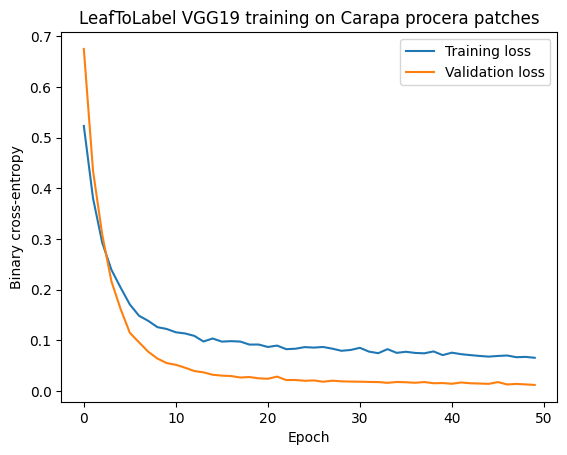

In [ ]:
# Save the Carapa procera model and plot losses (author cell 31)
model.save("/content/my_carapa_procera_model.keras")  # Keras 3 native format (author cell 31 saved a TF1-style folder)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Binary cross-entropy"); plt.legend()
plt.title("LeafToLabel VGG19 training on Carapa procera patches")
plt.show()

## 7. Sliding-window detection / スライディングウィンドウ検出

The trained model labels **overlapping 120×120 windows** (step 10 px) across the demo micrograph; windows with sigmoid output > **threshold 0.7** are kept (author cells 36–41). The paper determined this threshold. We keep the author's exact window geometry (`(H−120)//10` and `(W−120)//10` shifts plus the last offset window, centers at `x·shift + 60`) but **batch the predictions** instead of one `predict` per window — the same patches, weights and normalization, only faster. On the 1600×1200 demo image this is 16,241 windows.

**Expected result:** a positive-window count (a few hundred to a few thousand) with centers retained for clustering.
**期待される結果:** 閾値 0.7 を超えたウィンドウ（中心座標）のリスト。

In [ ]:
shift, patch_size = 10, 120  # author cell 36
threshold = 0.7               # author cell 40 (as determined in the paper)

no_x_shifts = (image.shape[0] - patch_size) // shift  # rows (author cell 38)
no_y_shifts = (image.shape[1] - patch_size) // shift  # cols
window_xy = [(x, y) for x in range(no_x_shifts + 1) for y in range(no_y_shifts + 1)]
n_windows = len(window_xy)
print(f"{n_windows} windows of {patch_size}x{patch_size} px, step {shift} px")

offset = patch_size // 2
stomata = []                      # positive-window centers [row_center, col_center] (author cell 41)
CHUNK = 1024                      # ~177 MB float32 per chunk; same patches and normalization as the author loop
for ci in range(0, n_windows, CHUNK):
    chunk = window_xy[ci : ci + CHUNK]
    patches = np.stack([
        image[x * shift : x * shift + patch_size, y * shift : y * shift + patch_size, :]
        for x, y in chunk])
    patches = patches.astype("float32") / 255.0  # author normalization
    y_model = model.predict(patches, verbose=0)
    keep = y_model[:, 0] > threshold
    stomata.extend([(x * shift + offset, y * shift + offset) for (x, y), k in zip(chunk, keep) if k])
    print(f"windows {ci}..{ci + len(chunk) - 1}: {int(keep.sum())} above threshold")

print(f"total positive windows: {len(stomata)}")
if len(stomata) == 0:
    raise RuntimeError("No window passed threshold 0.7; check the trained model before clustering.")


16241 windows of 120x120 px, step 10 px


windows 0..1023: 24 above threshold


windows 1024..2047: 29 above threshold


windows 2048..3071: 15 above threshold


windows 3072..4095: 60 above threshold


...

windows 11264..12287: 27 above threshold


windows 12288..13311: 26 above threshold


windows 13312..14335: 25 above threshold


windows 14336..15359: 9 above threshold


windows 15360..16240: 29 above threshold
total positive windows: 356


## 8. Mean-shift clustering / 平均シフト法によるクラスタリング

Overlapping positive windows are grouped by **mean-shift clustering** with `bandwidth = 60` (= patch_size // 2) and `bin_seeding=True` (author cell 43); each cluster center is one detected stoma. The tutorial then swaps the stored `[row, col]` pairs into `[x, y]` for plotting — preserved here verbatim.

**Expected result:** a detected-stoma count (typically a few dozen on the demo image).
**期待される結果:** 検出された気孔の数（デモ画像で数十程度）。

In [ ]:
from sklearn.cluster import MeanShift

bandwidth = patch_size // 2  # author cell 43
ms = MeanShift(bandwidth=bandwidth, bin_seeding=True)
ms.fit(stomata)
stomata_xy = np.array([[x[1], x[0]] for x in ms.cluster_centers_])  # cluster_centers_ is inverted (author comment)
print(f"detected stomata: {len(stomata_xy)} (from {len(stomata)} positive windows)")

detected stomata: 31 (from 356 positive windows)


## 9. Results / 結果の表示

Final plot in the style of the tutorial's output (author cell 45): the demo micrograph with detected stoma centers marked with red ×. We also export the coordinates as a small CSV. This figure is the reproduction's saved output (input image + model-prediction overlay, labeled as such).

**Expected result:** the micrograph with red × markers on detected stomata; a CSV with x/y pixel coordinates.
**期待される結果:** 検出された気孔に赤い × を重ねた図と、座標の CSV 出力。

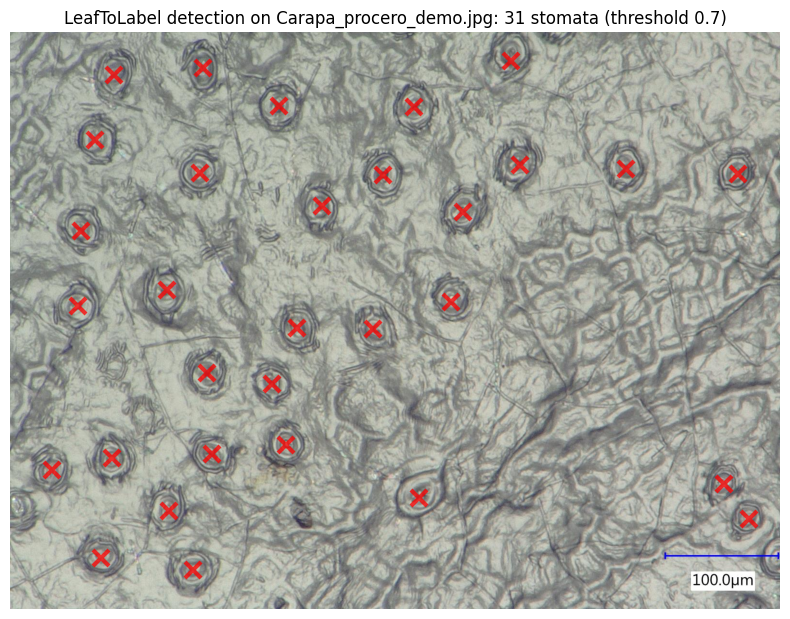

saved /content/detected_stomata.csv with 31 rows


In [ ]:
import csv
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.imshow(image)
ax.plot(stomata_xy[:, 0], stomata_xy[:, 1], "xr", alpha=0.75, markeredgewidth=3, markersize=12)
ax.set_title(f"LeafToLabel detection on Carapa_procero_demo.jpg: {len(stomata_xy)} stomata (threshold {threshold})")
ax.axis("off")
plt.show()

with open("/content/detected_stomata.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["x_px", "y_px"])
    w.writerows(np.round(stomata_xy, 1).tolist())
print("saved /content/detected_stomata.csv with", len(stomata_xy), "rows")

## 10. Interpretation, differences and validation record / 解釈と検証記録

**What was executed (validated on a fresh Colab T4 runtime, 2026-10-30):** the full tutorial path — Zenodo download with md5 verification, author-parameter training (50 epochs), threshold-0.7 sliding-window detection over 16,241 windows, and mean-shift clustering — producing the detection figure above.

**Adaptations (behavior-preserving, AI-assisted port):**
- TF1-era Keras imports → `tensorflow.keras` on TF 2.21 / Keras 3.13; `Adam(lr=...)` → `Adam(learning_rate=...)` (same value).
- Author's per-window `model.predict` loop → batched prediction of identical patches (same weights, normalization and window geometry).
- `model.save` target is the Keras 3 native `/content/my_carapa_procera_model.keras` file (the TF1 tutorial saved an unversioned folder, which Keras 3 rejects).

**Not reproduced / 本番の範囲外:** the hosted web service (kiks.ilabt.imec.be, unreachable at validation time; no author checkpoint file exists), the full multi-species study (Zenodo 3579227, Table S1), and any dataset-level accuracy claim. One didactic example does not verify the paper's published performance. CPU runtime runs the same cells but is not validated here and is markedly slower.

**References:**
- Meeus, Van den Bulcke & wyffels (2019), BISS 3:e37504, DOI 10.3897/biss.3.37504 (abstract).
- Meeus, Van den Bulcke & wyffels (2020), Ecol Evol 10:9178–9191, DOI 10.1002/ece3.6571 (journal version; Data Availability Statement points to the code and data used here).
- Code: github.com/fwyffels/LeafToLabel @ dc52c39a2f7cc704e32c2d85f8522e4f028c1f49, MIT License.
- Data: Zenodo 3902280, CC-BY-4.0 (training/validation patches + demo micrograph); full image archive Zenodo 3579227.